In [1]:
from pathlib import Path
import copy
import math
import numpy as np
import matplotlib.pyplot as plt

from pipeline import cifrar_imagen_completa, descifrar_imagen_completa
from io_imagen import obtener_rgb, filas_a_matrices_rgb, normalizar
from metricas import calcular_mse, calcular_psnr

base = Path().resolve().parent
ruta_imagen = base / "Imagenes" / "House.jpg"
R, G, B = obtener_rgb(str(ruta_imagen))
original = np.stack([np.array(R), np.array(G), np.array(B)], axis=-1)
cifrado = cifrar_imagen_completa(R, G, B)


In [2]:
# En este cifrado los bits R, G y B están intercalados por píxel en filas_RGB_cif.
def agregar_sal_pimienta(cifrado, densidad, semilla=42):
    alterado = copy.copy(cifrado)
    filas = np.array(cifrado.filas_RGB_cif, dtype=np.uint8)
    n_utiles = cifrado.w * 3 * cifrado.num_bits
    pixeles_bits = filas[:, :n_utiles].reshape(cifrado.h, cifrado.w, 3 * cifrado.num_bits).copy()

    rng = np.random.default_rng(semilla)
    mascara = rng.random((cifrado.h, cifrado.w))
    pixeles_bits[mascara < densidad / 2] = 0
    pixeles_bits[mascara >= 1 - densidad / 2] = 1

    filas[:, :n_utiles] = pixeles_bits.reshape(cifrado.h, n_utiles)
    alterado.filas_RGB_cif = list(filas)
    return alterado


def aplicar_oclusion(cifrado, porcentaje):
    alterado = copy.copy(cifrado)
    filas = np.array(cifrado.filas_RGB_cif, dtype=np.uint8)
    n_utiles = cifrado.w * 3 * cifrado.num_bits
    pixeles_bits = filas[:, :n_utiles].reshape(cifrado.h, cifrado.w, 3 * cifrado.num_bits).copy()

    lado = int(round(math.sqrt(porcentaje / 100 * cifrado.h * cifrado.w)))
    lado = max(1, min(lado, cifrado.h, cifrado.w))
    x_inicio = (cifrado.w - lado) // 2
    y_inicio = (cifrado.h - lado) // 2
    pixeles_bits[y_inicio:y_inicio + lado, x_inicio:x_inicio + lado] = 0

    filas[:, :n_utiles] = pixeles_bits.reshape(cifrado.h, n_utiles)
    alterado.filas_RGB_cif = list(filas)
    return alterado, (x_inicio, y_inicio, lado, lado)


def cifrado_a_imagen_visualizable(cifrado):
    r, g, b = filas_a_matrices_rgb(cifrado.filas_RGB_cif, cifrado.num_bits, cifrado.w)
    return np.stack([normalizar(canal) for canal in (r, g, b)], axis=-1)


def medir_reconstruccion(original, recuperada):
    return [(calcular_mse(original[:, :, i], recuperada[:, :, i]),
             calcular_psnr(original[:, :, i], recuperada[:, :, i])) for i in range(3)]


Densidad  MSE_R       MSE_G       MSE_B       PSNR_R    PSNR_G    PSNR_B    
0.001     57.708      41.660      39.797      30.5184   31.9337   32.1323   
0.005     262.792     231.855     223.908     23.9347   24.4786   24.6301   
0.01      541.982     469.228     468.298     20.7910   21.4170   21.4256   
0.05      2420.511    2069.192    2003.512    14.2917   14.9728   15.1129   


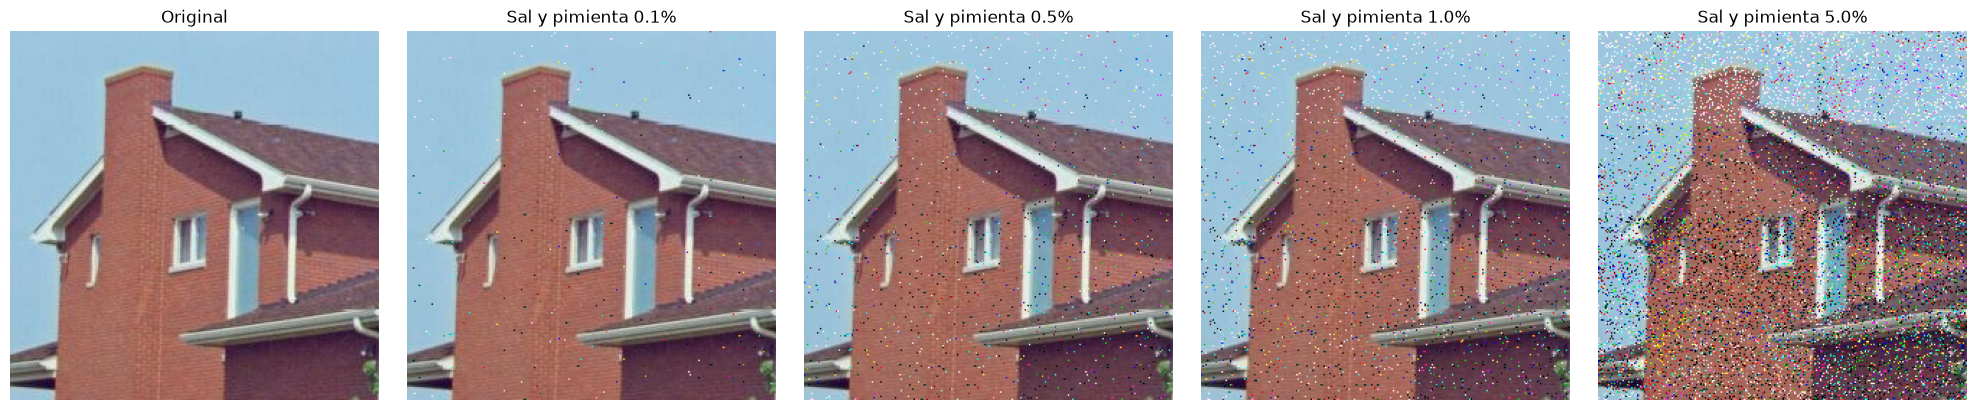

In [3]:
# Sal y pimienta sobre los bits cifrados; las demás capas permanecen intactas.
densidades_sal_pimienta = [0.001, 0.005, 0.010, 0.050]
fig, axes = plt.subplots(1, len(densidades_sal_pimienta) + 1,
                         figsize=(4 * (len(densidades_sal_pimienta) + 1), 4))
axes[0].imshow(original)
axes[0].set_title("Original")
axes[0].axis("off")

print(f"{'Densidad':<10}{'MSE_R':<12}{'MSE_G':<12}{'MSE_B':<12}{'PSNR_R':<10}{'PSNR_G':<10}{'PSNR_B':<10}")
for ax, densidad in zip(axes[1:], densidades_sal_pimienta):
    recuperada = descifrar_imagen_completa(agregar_sal_pimienta(cifrado, densidad))
    medidas = medir_reconstruccion(original, recuperada)
    print(f"{densidad:<10}{medidas[0][0]:<12.3f}{medidas[1][0]:<12.3f}{medidas[2][0]:<12.3f}"
          f"{medidas[0][1]:<10.4f}{medidas[1][1]:<10.4f}{medidas[2][1]:<10.4f}")
    ax.imshow(recuperada)
    ax.set_title(f"Sal y pimienta {densidad:.1%}")
    ax.axis("off")
plt.tight_layout()
plt.show()


Oclusión  MSE_R       MSE_G       MSE_B       PSNR_R    PSNR_G    PSNR_B    
10        3627.064    3086.829    2947.499    12.5353   13.2357   13.4363   
25        6442.201    5039.818    4433.390    10.0405   11.1067   11.6634   
50        10940.483   9234.379    8579.356    7.7404    8.4767    8.7963    
75        13960.909   12276.166   11797.661   6.6817    7.2402    7.4128    


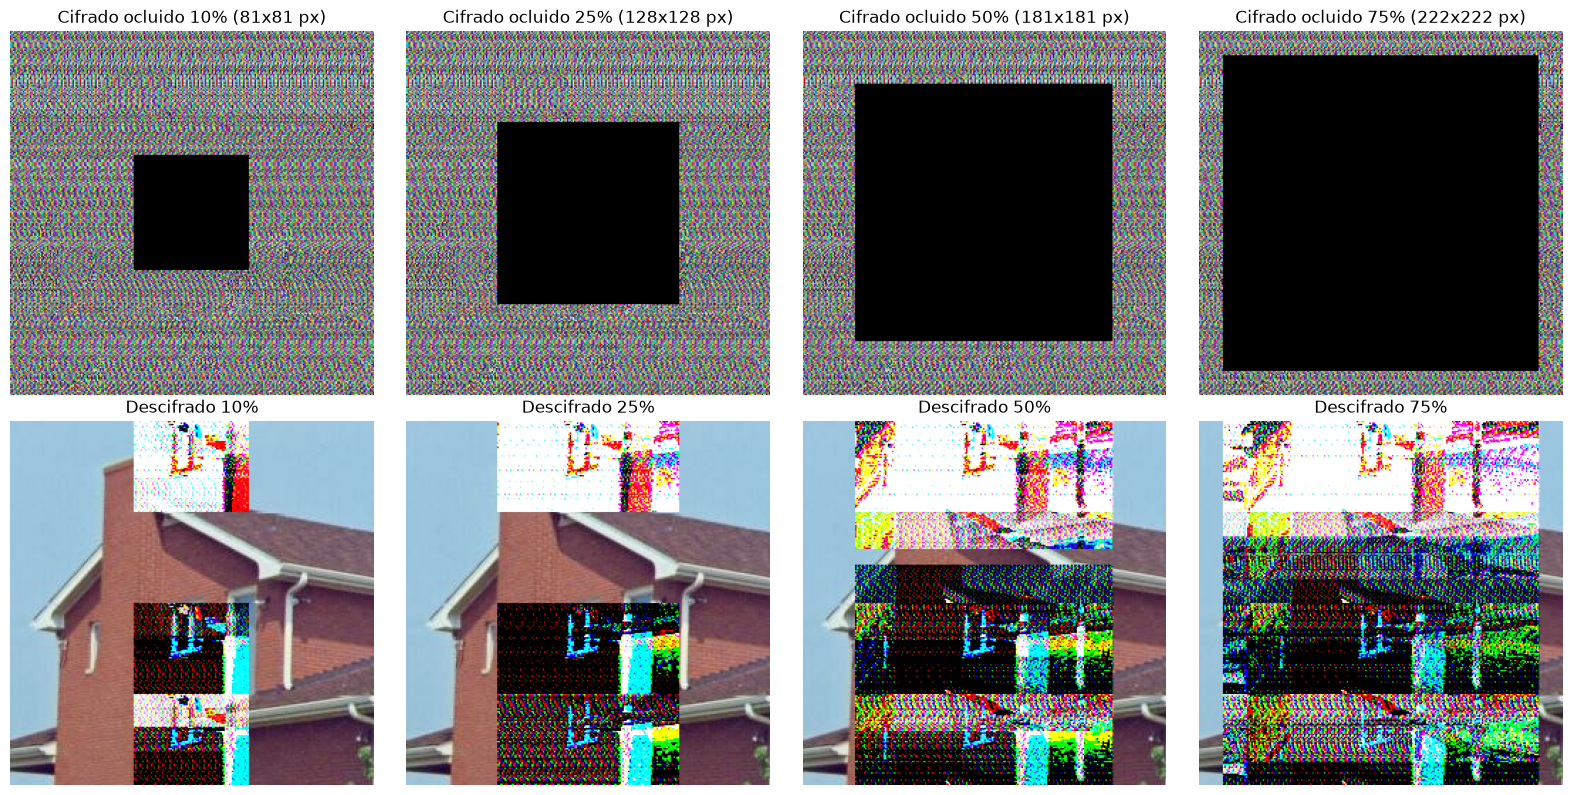

In [4]:
# Oclusión de un bloque central de la parte real cifrada.
porcentajes_oclusion = [10, 25, 50, 75]
fig, axes = plt.subplots(2, len(porcentajes_oclusion),
                         figsize=(4 * len(porcentajes_oclusion), 8))

print(f"{'Oclusión':<10}{'MSE_R':<12}{'MSE_G':<12}{'MSE_B':<12}{'PSNR_R':<10}{'PSNR_G':<10}{'PSNR_B':<10}")
for col, porcentaje in enumerate(porcentajes_oclusion):
    cifrado_ocluido, bloque = aplicar_oclusion(cifrado, porcentaje)
    recuperada = descifrar_imagen_completa(cifrado_ocluido)
    medidas = medir_reconstruccion(original, recuperada)
    print(f"{porcentaje:<10}{medidas[0][0]:<12.3f}{medidas[1][0]:<12.3f}{medidas[2][0]:<12.3f}"
          f"{medidas[0][1]:<10.4f}{medidas[1][1]:<10.4f}{medidas[2][1]:<10.4f}")

    axes[0, col].imshow(cifrado_a_imagen_visualizable(cifrado_ocluido))
    axes[0, col].set_title(f"Cifrado ocluido {porcentaje}% ({bloque[2]}x{bloque[3]} px)")
    axes[0, col].axis("off")
    axes[1, col].imshow(recuperada)
    axes[1, col].set_title(f"Descifrado {porcentaje}%")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()
